In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Percaktojme folderin kryesor
project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

data_path = project_path / "data" / "processed"
models_path = project_path / "models"
reports_path = project_path / "docs" / "final_evaluation"

reports_path.mkdir(parents=True, exist_ok=True)

print("Project:", project_path)
print("Libraries imported successfully!")

Project: c:\Projects\Bachelor-Thesis
Libraries imported successfully!


In [2]:
# Ngarkojme modelin e zgjedhur ne Validation
model_path = models_path / "svm_tuned_validation.joblib"

model_svm = joblib.load(model_path)

# Ngarkojme ndarjet ekzistuese
train_df = pd.read_csv(data_path / "train.csv")
val_df = pd.read_csv(data_path / "validation.csv")
test_df = pd.read_csv(data_path / "test.csv")

print("FINAL MODEL EVALUATION")
print("=" * 45)

print("Model: Tuned LinearSVC")
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nModel parameters:")
print(model_svm.get_params()["classifier__C"])
print(model_svm.get_params()["tfidf__ngram_range"])

assert len(train_df) == 803
assert len(val_df) == 178
assert len(test_df) == 172

print("\nDataset sizes verified successfully!")

FINAL MODEL EVALUATION
Model: Tuned LinearSVC
Training samples: 803
Validation samples: 178
Testing samples: 172

Model parameters:
10
(1, 1)

Dataset sizes verified successfully!


In [3]:
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

train_val_overlap = len(train_groups & val_groups)
train_test_overlap = len(train_groups & test_groups)
val_test_overlap = len(val_groups & test_groups)

print("DATA SPLIT VERIFICATION")
print("=" * 45)

print("Training / Validation overlap:", train_val_overlap)
print("Training / Testing overlap:", train_test_overlap)
print("Validation / Testing overlap:", val_test_overlap)

assert train_val_overlap == 0
assert train_test_overlap == 0
assert val_test_overlap == 0

print("\nNo shared group IDs across splits!")

DATA SPLIT VERIFICATION
Training / Validation overlap: 0
Training / Testing overlap: 0
Validation / Testing overlap: 0

No shared group IDs across splits!


In [4]:
# Final Testing - ekzekutohet pas verifikimeve
X_test = test_df["text"]
y_test = test_df["label"]

# Parashikimet e modelit te ngrire
y_pred = model_svm.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

correct = (y_test.to_numpy() == y_pred).sum()
incorrect = len(y_test) - correct

print("FINAL TEST RESULTS - SVM")
print("=" * 45)

print(f"Accuracy:        {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1:        {f1:.4f}")

print(f"\nCorrect predictions:   {correct}")
print(f"Incorrect predictions: {incorrect}")

FINAL TEST RESULTS - SVM
Accuracy:        0.9884
Macro Precision: 0.9894
Macro Recall:    0.9836
Macro F1:        0.9852

Correct predictions:   170
Incorrect predictions: 2


In [5]:
report = classification_report(
    y_test,
    y_pred,
    labels=model_svm.named_steps["classifier"].classes_,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print("=" * 60)
print(report)

# Ruajme rezultatet per cdo klase
report_dict = classification_report(
    y_test,
    y_pred,
    labels=model_svm.named_steps["classifier"].classes_,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    reports_path / "svm_classification_report.csv"
)

print("\nClassification report saved!")

CLASSIFICATION REPORT
                                 precision    recall  f1-score   support

                           Acne       1.00      1.00      1.00         7
                      Arthritis       1.00      1.00      1.00         9
               Bronchial Asthma       1.00      1.00      1.00         9
           Cervical spondylosis       1.00      1.00      1.00         7
                    Chicken pox       1.00      1.00      1.00         8
                    Common Cold       0.89      1.00      0.94         8
                         Dengue       1.00      1.00      1.00         9
          Dimorphic Hemorrhoids       1.00      1.00      1.00         8
               Fungal infection       1.00      1.00      1.00         5
                   Hypertension       1.00      1.00      1.00         6
                       Impetigo       1.00      1.00      1.00         7
                       Jaundice       1.00      1.00      1.00         6
                        Mala

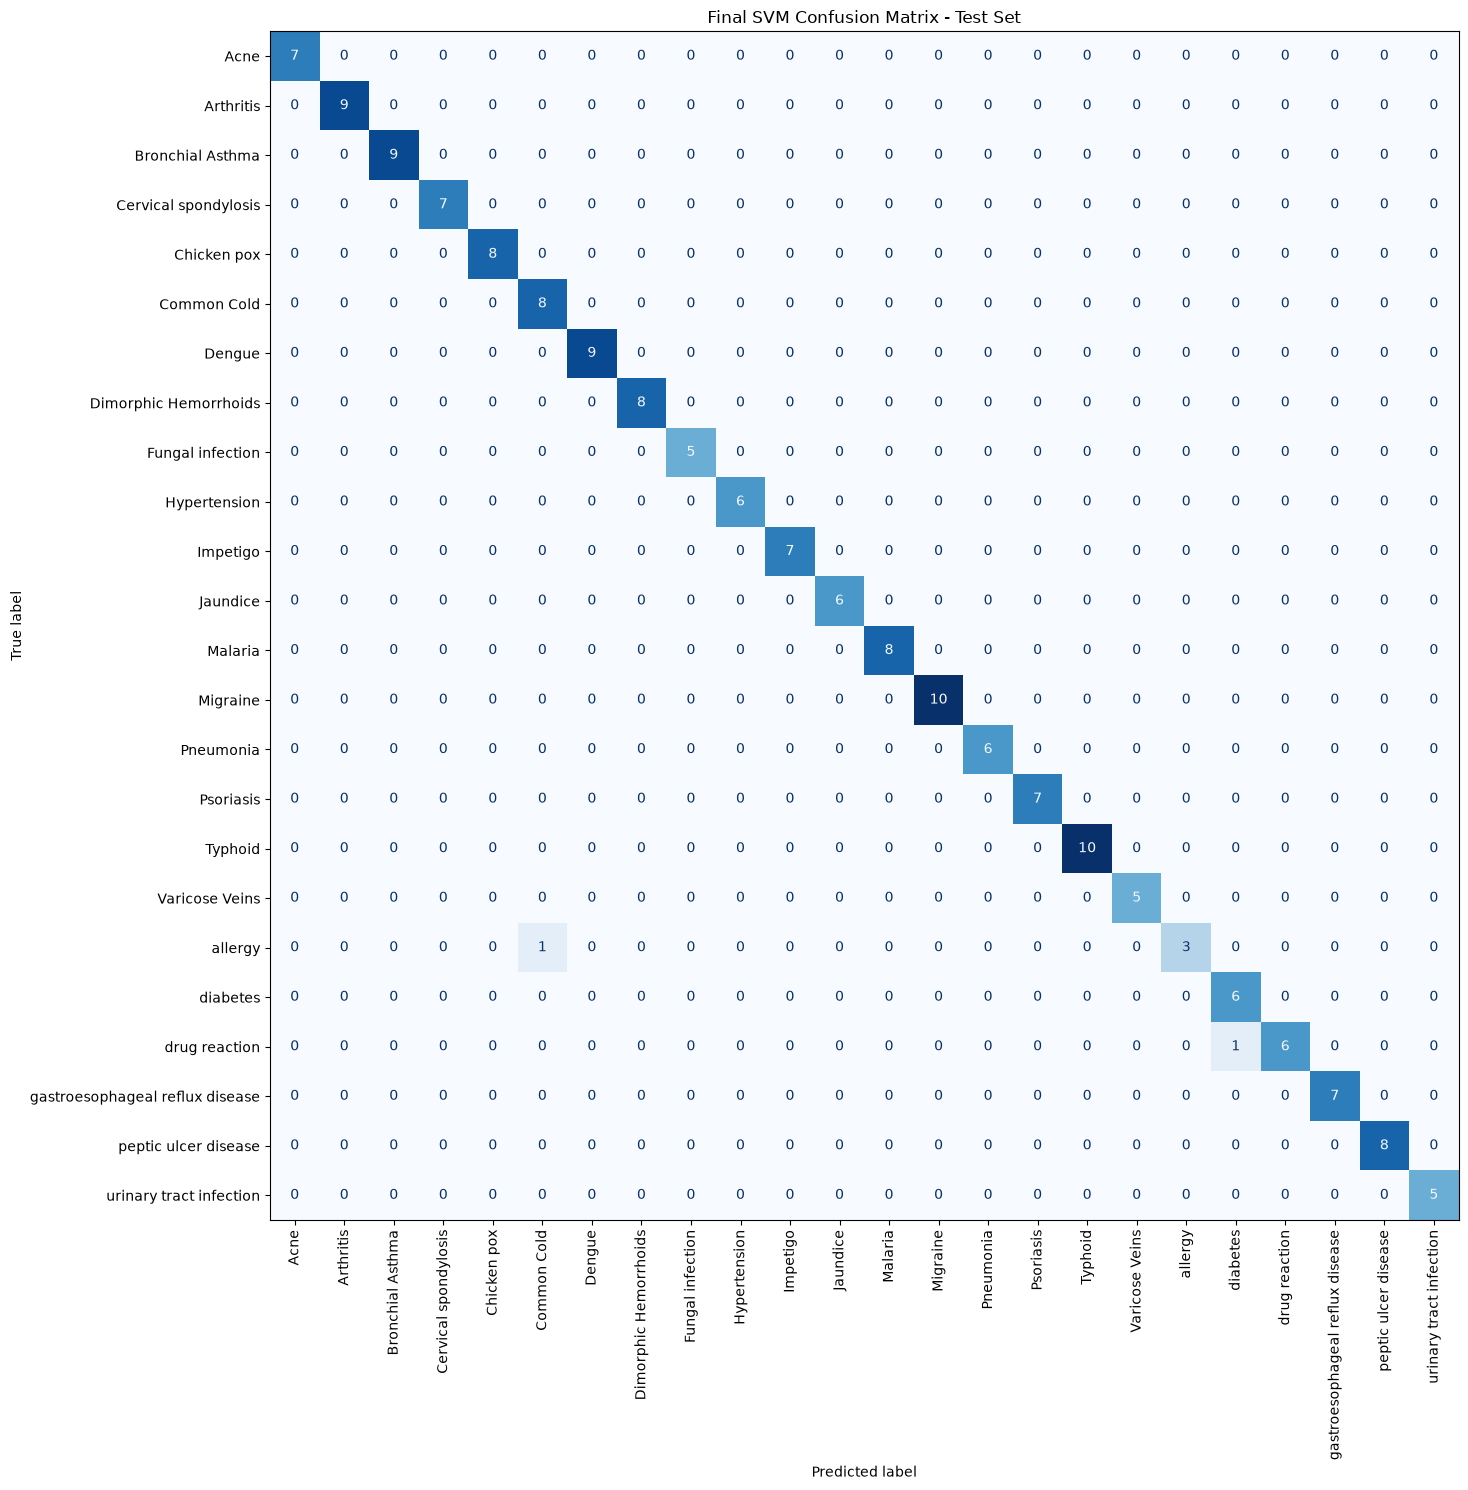

In [6]:
class_names = list(
    model_svm.named_steps["classifier"].classes_
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_names
)

fig, ax = plt.subplots(figsize=(17, 15))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title("Final SVM Confusion Matrix - Test Set")
plt.tight_layout()

plt.savefig(
    reports_path / "svm_final_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [7]:
results = pd.DataFrame([{
    "Model": "Tuned LinearSVC",
    "Training Samples": len(train_df),
    "Validation Samples": len(val_df),
    "Testing Samples": len(test_df),
    "Accuracy": accuracy,
    "Macro Precision": precision,
    "Macro Recall": recall,
    "Macro F1": f1,
    "Correct Predictions": int(correct),
    "Incorrect Predictions": int(incorrect)
}])

results.to_csv(
    reports_path / "svm_final_test_results.csv",
    index=False
)

# Ruajme parashikimet per analize
predictions_df = test_df[
    ["label", "text"]
].copy()

predictions_df["predicted_label"] = y_pred

predictions_df["correct"] = (
    predictions_df["label"]
    == predictions_df["predicted_label"]
)

predictions_df.to_csv(
    reports_path / "svm_test_predictions.csv",
    index=False
)

# Raporti tekstual
with open(
    reports_path / "final_evaluation_report.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("FINAL MODEL EVALUATION\n")
    f.write("=" * 50 + "\n\n")

    f.write("Model: Tuned LinearSVC\n")
    f.write("Training: Original data (no augmentation)\n")
    f.write(f"Training samples: {len(train_df)}\n")
    f.write(f"Validation samples: {len(val_df)}\n")
    f.write(f"Testing samples: {len(test_df)}\n\n")

    f.write(f"Accuracy: {accuracy:.6f}\n")
    f.write(f"Macro Precision: {precision:.6f}\n")
    f.write(f"Macro Recall: {recall:.6f}\n")
    f.write(f"Macro F1: {f1:.6f}\n")
    f.write(f"Correct: {correct}\n")
    f.write(f"Incorrect: {incorrect}\n\n")

    f.write("CLASSIFICATION REPORT\n")
    f.write(report)

print("Final evaluation files saved!")
print("Location:", reports_path)

Final evaluation files saved!
Location: c:\Projects\Bachelor-Thesis\docs\final_evaluation


In [8]:
errors_df = predictions_df[
    predictions_df["correct"] == False
]

print("FINAL TESTING - INCORRECT PREDICTIONS")
print("=" * 55)
print("Total errors:", len(errors_df))

for _, row in errors_df.iterrows():
    print("\nActual disease:", row["label"])
    print("Predicted disease:", row["predicted_label"])
    print("Symptoms:", row["text"])
    print("-" * 55)

FINAL TESTING - INCORRECT PREDICTIONS
Total errors: 2

Actual disease: allergy
Predicted disease: Common Cold
Symptoms: I always feel exhausted, have a bad taste in my mouth, and my throat itches a lot. Also heated and painful are my muscles. My entire body can cramp up at times.
-------------------------------------------------------

Actual disease: drug reaction
Predicted disease: diabetes
Symptoms: I no longer want to have sex, and it's difficult for me to do so. I regularly have brain fog and a sense of confusion.
-------------------------------------------------------


In [9]:
error_analysis = pd.DataFrame([
    {
        "Actual": "allergy",
        "Predicted": "Common Cold",
        "Interpretation": (
            "Non-specific symptoms and possible "
            "overlap in textual descriptions."
        )
    },
    {
        "Actual": "drug reaction",
        "Predicted": "diabetes",
        "Interpretation": (
            "Symptoms lack medication context; "
            "possible learned statistical associations."
        )
    }
])

error_analysis.to_csv(
    reports_path / "svm_error_analysis.csv",
    index=False
)

print("Error analysis saved successfully!")
display(error_analysis)

Error analysis saved successfully!


,Actual,Predicted,Interpretation
0,allergy,Common Cold,Non-specific symptoms and possible overlap in ...
1,drug reaction,diabetes,Symptoms lack medication context; possible lea...
